<span style="font-size:2em;">Instructor: Dr. Qipei (Gavin) Mei (qipei.mei@ualberta.ca); Yuezhen Gao (yuezhen@ualberta.ca)</span>

<span style="font-size:2em;">Student Name: Amilcar Díaz</span>

<span style="font-size:2em;">CCID: adiazgar</span>

# Question 1: Predicción de la resistencia a compresión del concreto con una red neuronal [30 Marks]

**Objetivo.** Construir una red neuronal que prediga la resistencia a compresión del concreto $f'_c$ (MPa) a partir de la dosificación de la mezcla (7 componentes, en kg por m³ de mezcla) y de la edad del concreto al momento del ensayo (días).

**Datos.** Resultados experimentales publicados por Yeh (1998), entregados ya divididos en dos archivos: `train-val.csv` (824 muestras), para entrenar y validar los modelos, y `test.csv` (206 muestras), reservado para la evaluación final.

**Entregable.** Un reporte con tablas y figuras que documente el trabajo realizado y cumpla los seis requisitos del enunciado (Tabla 1, sección 0).

## 0. Seguimiento de los requisitos

**Tabla 1.** Requisitos del enunciado y sección del notebook donde se cumple cada uno.

| # | Requisito del enunciado | Sección donde se cumple |
|---|---|---|
| 1 | Construir un modelo de red neuronal | 6 |
| 2 | Revisar y evitar problemas de sesgo y varianza | 7 y 9 |
| 3 | Evaluar los modelos con validación cruzada k-fold | 4 |
| 4 | Elegir una sola métrica y justificarla | 3 |
| 5 | Mostrar el esfuerzo por mejorar el desempeño del modelo | 8 |
| 6 | Reportar el desempeño en el conjunto de prueba | 9 |

## 1. Configuración

En esta sección se cargan las librerías y se fijan los parámetros que se usan en todo el notebook:

- **Semilla fija** (`SEED = 42`): todos los procesos aleatorios (partición en folds, inicialización de los pesos de la red, búsquedas de hiperparámetros) usan esta semilla, de modo que al volver a ejecutar el notebook se obtienen exactamente los mismos resultados.
- **Particiones k-fold**: se definen una sola vez, con $K = 10$ y mezclando las muestras antes de dividirlas (`shuffle=True`). Así todos los modelos se comparan con las mismas particiones, y las diferencias entre ellos se deben al modelo y no a la forma en que se dividieron los datos. Con unas 800 muestras, cada fold de validación tiene alrededor de 80 muestras. La justificación completa del k-fold se presenta en la sección 4.
- **Nombres cortos de las columnas**: los nombres originales de los archivos CSV son largos e incluyen las unidades, así que se reemplazan por nombres cortos en inglés (Tabla 2, sección 2.1).
- **Numeración y leyendas**: todas las tablas, ecuaciones y figuras se numeran en orden de aparición, y el texto se refiere a ellas por su número. Se sigue el formato académico estándar: la leyenda de cada tabla va encima de la tabla, la de cada figura va debajo de la figura, y el número de cada ecuación va a la derecha, entre paréntesis. Las leyendas de las tablas y figuras generadas por código se agregan con las funciones `show_table` y `show_figure`.
- **Etiquetas de los ejes y nombres de las columnas**: se escriben en inglés, porque el reporte final se entrega en ese idioma.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.colors import ListedColormap, LogNorm
from sklearn.model_selection import KFold

# Reproducibility: every random process in the notebook uses this seed
SEED = 42
np.random.seed(SEED)

# Data files (same folder as this notebook)
DATA_DIR = Path(".")
TRAIN_VAL_FILE = DATA_DIR / "train-val.csv"
TEST_FILE = DATA_DIR / "test.csv"

# Short column names, in the same order as in the CSV files
FEATURES = ["cement", "slag", "fly_ash", "water", "superplasticizer",
            "coarse_agg", "fine_agg", "age"]
TARGET = "strength"
COLUMNS = FEATURES + [TARGET]

# Axis labels for the figures
LABELS = {
    "cement": "Cement (kg/m³)",
    "slag": "Blast furnace slag (kg/m³)",
    "fly_ash": "Fly ash (kg/m³)",
    "water": "Water (kg/m³)",
    "superplasticizer": "Superplasticizer (kg/m³)",
    "coarse_agg": "Coarse aggregate (kg/m³)",
    "fine_agg": "Fine aggregate (kg/m³)",
    "age": "Age (days)",
    "strength": "Compressive strength (MPa)",
}

# K-fold partitions, defined once so that every experiment uses the same folds
N_FOLDS = 10
kfold = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

# Figure style
COLOR_TRAIN = "#2a78d6"   # train-val data
COLOR_TEST = "#eb6834"    # test data
COLOR_MUTED = "#52514e"   # secondary text and reference lines
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e6e6",
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "legend.frameon": False,
})
pd.set_option("display.precision", 2)

def show_table(df, number, caption, precision=2, hide_index=False):
    """Display a DataFrame with its numbered caption above it (academic format)."""
    display(Markdown(f"**Tabla {number}.** {caption}"))
    styled = df.style.format(precision=precision)
    display(styled.hide(axis="index") if hide_index else styled)


def show_figure(fig, number, caption):
    """Display a figure with its numbered caption below it (academic format)."""
    display(fig)
    plt.close(fig)
    display(Markdown(f"**Figura {number}.** {caption}"))

## 2. Datos y análisis exploratorio

### 2.1 Carga de los datos

Se leen los dos archivos y se reemplazan los nombres de las columnas por los nombres cortos definidos en la sección 1. Ambos archivos tienen las mismas 9 columnas en el mismo orden: 8 variables de entrada y la resistencia a compresión como variable de salida.

In [2]:
# Read both files (utf-8-sig removes the byte order mark at the start of the header)
train_val_raw = pd.read_csv(TRAIN_VAL_FILE, encoding="utf-8-sig")
test_raw = pd.read_csv(TEST_FILE, encoding="utf-8-sig")

# Both files must have the same columns, in the same order
assert list(train_val_raw.columns) == list(test_raw.columns)

# Replace the long original names with the short ones (by position)
train_val_df = train_val_raw.set_axis(COLUMNS, axis=1)
test_df = test_raw.set_axis(COLUMNS, axis=1)

print(f"train-val: {train_val_df.shape[0]} samples, {train_val_df.shape[1]} columns")
print(f"test:      {test_df.shape[0]} samples, {test_df.shape[1]} columns")

# Equivalence between original and short column names
UNITS = ["kg/m³"] * 7 + ["days", "MPa"]
ROLES = ["input"] * 8 + ["output"]
column_names = pd.DataFrame({"original name": train_val_raw.columns.str.strip(),
                             "short name": COLUMNS,
                             "unit": UNITS,
                             "role": ROLES})
show_table(column_names, 2,
           "Equivalencia entre los nombres originales de las columnas y los nombres cortos usados en el notebook.",
           hide_index=True)

train-val: 824 samples, 9 columns
test:      206 samples, 9 columns


**Tabla 2.** Equivalencia entre los nombres originales de las columnas y los nombres cortos usados en el notebook.

original name,short name,unit,role
Cement (component 1)(kg in a m^3 mixture),cement,kg/m³,input
Blast Furnace Slag (component 2)(kg in a m^3 mixture),slag,kg/m³,input
Fly Ash (component 3)(kg in a m^3 mixture),fly_ash,kg/m³,input
Water (component 4)(kg in a m^3 mixture),water,kg/m³,input
Superplasticizer (component 5)(kg in a m^3 mixture),superplasticizer,kg/m³,input
Coarse Aggregate (component 6)(kg in a m^3 mixture),coarse_agg,kg/m³,input
Fine Aggregate (component 7)(kg in a m^3 mixture),fine_agg,kg/m³,input
Age (day),age,days,input
"Concrete compressive strength(MPa, megapascals)",strength,MPa,output


La Tabla 3 resume las estadísticas descriptivas del conjunto train-val, antes de revisar duplicados.

In [3]:
show_table(train_val_df.describe().T, 3,
           "Estadísticas descriptivas del conjunto train-val (824 muestras, antes de eliminar duplicados).")

**Tabla 3.** Estadísticas descriptivas del conjunto train-val (824 muestras, antes de eliminar duplicados).

,count,mean,std,min,25%,50%,75%,max
cement,824.00,279.96,103.88,102.00,193.12,266.00,350.00,540.00
slag,824.00,73.46,85.72,0.00,0.00,22.00,144.70,359.40
fly_ash,824.00,55.21,64.07,0.00,0.00,0.00,118.30,200.10
water,824.00,181.27,21.54,121.80,164.90,185.00,192.00,246.90
superplasticizer,824.00,6.29,5.96,0.00,0.00,6.65,10.40,32.20
coarse_agg,824.00,975.23,78.72,801.00,932.00,968.00,1040.60,1145.00
fine_agg,824.00,772.35,80.29,594.00,734.00,778.50,822.20,992.60
age,824.00,46.92,64.80,1.00,12.25,28.00,56.00,365.00
strength,824.00,35.76,16.44,3.32,23.80,34.22,45.32,82.60


**Comparación con la Tabla 1 del artículo de Yeh (1998).** El artículo describe una base de datos de 727 registros, mientras que el curso entrega 1030 (824 + 206). La Tabla 4 compara los rangos de los componentes de la mezcla en ambos casos (la Tabla 1 del artículo de Yeh no incluye la edad ni la resistencia).

In [4]:
# Table 1 of Yeh (1998): ranges of the mix components in the original database (727 records)
yeh_table1 = pd.DataFrame(
    {"min": [71, 0, 0, 120, 0, 730, 486],
     "max": [600, 359, 175, 228, 20.8, 1322, 968],
     "mean": [232.2, 79.2, 46.4, 186.4, 3.5, 943.5, 819.9]},
    index=["cement", "slag", "fly_ash", "water", "superplasticizer", "coarse_agg", "fine_agg"],
)
train_val_ranges = train_val_df[yeh_table1.index].agg(["min", "max", "mean"]).T
range_comparison = pd.concat({"Yeh (1998), 727 records": yeh_table1,
                              "train-val, 824 samples": train_val_ranges}, axis=1)
show_table(range_comparison, 4,
           "Rangos de los componentes de la mezcla (kg/m³) en la Tabla 1 del artículo de Yeh (1998) "
           "y en train-val.", precision=1)

**Tabla 4.** Rangos de los componentes de la mezcla (kg/m³) en la Tabla 1 del artículo de Yeh (1998) y en train-val.

Los rangos no coinciden: por ejemplo, en train-val el superplastificante llega a 32.2 kg/m³ (20.8 en Yeh), el agua a 246.9 kg/m³ (228 en Yeh) y el agregado grueso solo hasta 1145 kg/m³ (1322 en Yeh). Esto indica que el dataset del curso no es exactamente el del artículo, sino una versión distinta y más amplia de la base de datos. Por lo tanto, los resultados de Yeh sirven como referencia del orden de magnitud esperado, pero no son directamente comparables con los de este trabajo.

**Rango de las variables de entrada del conjunto de prueba.** Una red neuronal no extrapola bien fuera del dominio de los datos con que se entrenó; Yeh (1998) lo señala como una limitación del método. Por eso se verifica que las entradas del conjunto de prueba estén dentro del rango de train-val (Tabla 5). Solo se revisan las variables de entrada: la resistencia del conjunto de prueba no se examina en esta etapa, para que no influya en ninguna decisión sobre el modelo.

In [5]:
# Number of test samples whose input values fall outside the train-val range
below_range = test_df[FEATURES] < train_val_df[FEATURES].min()
above_range = test_df[FEATURES] > train_val_df[FEATURES].max()
input_ranges = pd.DataFrame({"train-val min": train_val_df[FEATURES].min(),
                             "train-val max": train_val_df[FEATURES].max(),
                             "test min": test_df[FEATURES].min(),
                             "test max": test_df[FEATURES].max(),
                             "test samples outside range": (below_range | above_range).sum()})
show_table(input_ranges, 5,
           "Rangos de las variables de entrada en train-val y en prueba, y número de muestras de prueba "
           "fuera del rango de train-val.",
           precision=1)

**Tabla 5.** Rangos de las variables de entrada en train-val y en prueba, y número de muestras de prueba fuera del rango de train-val.

,train-val min,train-val max,test min,test max,test samples outside range
cement,102.0,540.0,102.0,540.0,0
slag,0.0,359.4,0.0,359.4,0
fly_ash,0.0,200.1,0.0,195.0,0
water,121.8,246.9,126.6,247.0,1
superplasticizer,0.0,32.2,0.0,32.2,0
coarse_agg,801.0,1145.0,817.9,1125.0,0
fine_agg,594.0,992.6,594.0,992.6,0
age,1.0,365.0,3.0,365.0,0


Solo una muestra de prueba queda fuera del rango, y por muy poco: tiene 247.0 kg/m³ de agua, frente a un máximo de 246.9 kg/m³ en train-val. En la práctica, el conjunto de prueba está dentro del dominio de los datos de entrenamiento, así que la evaluación final medirá la capacidad de **interpolación** del modelo.

### 2.2 Calidad de los datos

Se revisan tres aspectos: valores faltantes, muestras duplicadas dentro de train-val y muestras del conjunto de prueba cuya mezcla también aparece en train-val.

**Valores faltantes**

In [6]:
missing_values = pd.DataFrame({"train-val": train_val_df.isna().sum(),
                               "test": test_df.isna().sum()}).T
show_table(missing_values, 6, "Número de valores faltantes por columna.")

**Tabla 6.** Número de valores faltantes por columna.

,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
train-val,0,0,0,0,0,0,0,0,0
test,0,0,0,0,0,0,0,0,0


No hay valores faltantes en ninguno de los dos archivos (Tabla 6).

**Duplicados exactos en train-val.** Un duplicado exacto es una fila con los mismos valores en las 9 columnas. Si se deja en los datos, al hacer la validación cruzada una copia puede quedar en el fold de entrenamiento y la otra en el de validación: la red ya "vio" esa muestra durante el entrenamiento, y el error de validación resulta más optimista de lo que debería.

In [7]:
# Exact duplicates: identical values in all 9 columns
is_duplicate = train_val_df.duplicated(keep="first")
print(f"Exact duplicates in train-val: {is_duplicate.sum()} of {len(train_val_df)} samples")

# First rows involved in duplication (each original together with its copies)
show_table(train_val_df[train_val_df.duplicated(keep=False)].sort_values(COLUMNS).head(10), 7,
           "Primeras filas de train-val que forman parte de un duplicado exacto "
           "(cada muestra junto con sus copias).")

Exact duplicates in train-val: 19 of 824 samples


**Tabla 7.** Primeras filas de train-val que forman parte de un duplicado exacto (cada muestra junto con sus copias).

,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
513,252.00,0.00,0.00,185.00,0.00,1111.00,784.00,28,19.69
628,252.00,0.00,0.00,185.00,0.00,1111.00,784.00,28,19.69
177,362.60,189.00,0.00,164.90,11.60,944.70,755.80,3,35.30
564,362.60,189.00,0.00,164.90,11.60,944.70,755.80,3,35.30
692,362.60,189.00,0.00,164.90,11.60,944.70,755.80,3,35.30
80,362.60,189.00,0.00,164.90,11.60,944.70,755.80,7,55.90
347,362.60,189.00,0.00,164.90,11.60,944.70,755.80,7,55.90
737,362.60,189.00,0.00,164.90,11.60,944.70,755.80,7,55.90
142,362.60,189.00,0.00,164.90,11.60,944.70,755.80,28,71.30
675,362.60,189.00,0.00,164.90,11.60,944.70,755.80,28,71.30


En los ejemplos de la Tabla 7, una misma mezcla ensayada a la misma edad aparece dos o tres veces con exactamente la misma resistencia.

**Decisión:** se eliminan los duplicados exactos y se conserva una sola copia de cada muestra.

In [8]:
train_val_df = train_val_df.drop_duplicates(keep="first").reset_index(drop=True)
print(f"train-val after removing exact duplicates: {len(train_val_df)} samples")

train-val after removing exact duplicates: 805 samples


**Misma mezcla y misma edad, distinta resistencia.** Después de eliminar los duplicados exactos todavía quedan grupos de muestras con las mismas 8 variables de entrada pero con una resistencia distinta (Tabla 8).

In [9]:
# Groups of samples with identical inputs (same mix and age) but different strength
repeated_mixes = (train_val_df.groupby(FEATURES)[TARGET]
                  .agg(n_samples="count", min_strength="min", max_strength="max")
                  .query("n_samples > 1"))
repeated_mixes["difference"] = repeated_mixes["max_strength"] - repeated_mixes["min_strength"]
print(f"{len(repeated_mixes)} groups with repeated inputs, "
      f"{repeated_mixes['n_samples'].sum()} samples in total")
show_table(repeated_mixes.reset_index(), 8,
           "Grupos de muestras de train-val con las mismas entradas (mezcla y edad) "
           "pero distinta resistencia.",
           hide_index=True)

7 groups with repeated inputs, 16 samples in total


**Tabla 8.** Grupos de muestras de train-val con las mismas entradas (mezcla y edad) pero distinta resistencia.

cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,n_samples,min_strength,max_strength,difference
359.00,19.00,141.00,154.00,10.90,942.00,801.00,28,2,59.49,62.94,3.45
359.00,19.00,141.00,154.00,10.90,942.00,801.00,56,2,66.78,68.75,1.97
362.60,189.00,0.00,164.90,11.60,944.70,755.80,7,2,22.90,55.90,33.00
446.00,24.00,79.00,162.00,11.60,967.00,712.00,3,2,23.35,25.02,1.67
446.00,24.00,79.00,162.00,11.60,967.00,712.00,7,3,38.02,52.01,13.99
446.00,24.00,79.00,162.00,11.60,967.00,712.00,28,3,44.42,57.03,12.61
446.00,24.00,79.00,162.00,11.60,967.00,712.00,56,2,56.14,61.07,4.93


Son ensayos repetidos de una misma mezcla a la misma edad, así que la diferencia entre sus resultados refleja la dispersión propia del ensayo de compresión. En cuatro de los siete grupos de la Tabla 8 la diferencia es menor de 5 MPa y en otros dos es de 13 a 14 MPa. En el grupo restante llega a 33 MPa (22.9 y 55.9 MPa a los 7 días), lo que parece demasiado para ser solo dispersión y podría ser un error de registro, pero no hay forma de saber cuál de los dos valores es el correcto.

**Decisión:** se conservan, porque son información experimental real. Esto tiene dos consecuencias:

1. Ningún modelo puede alcanzar un error cero, porque unas mismas entradas tienen salidas distintas. Existe un **error irreducible** debido a la variabilidad experimental.
2. Como estas muestras comparten las entradas, puede ocurrir la misma fuga de información descrita para los duplicados exactos, aunque su efecto es menor (16 de 805 muestras, el 2 %). Este punto se retoma en la sección 4.

**Muestras de prueba cuya mezcla también aparece en train-val.** Para esta revisión solo se comparan las variables de entrada (mezcla y edad), sin mirar la resistencia del conjunto de prueba.

In [10]:
# Test samples whose inputs (mix and age) also appear in train-val
train_val_mixes = train_val_df[FEATURES].drop_duplicates()
test_seen_mix = (test_df[FEATURES]
                 .merge(train_val_mixes, how="left", indicator=True)["_merge"]
                 .eq("both")
                 .to_numpy())

print(f"Test samples with repeated inputs within test: {test_df.duplicated(subset=FEATURES).sum()}")
print(f"Test samples whose mix and age also appear in train-val: "
      f"{test_seen_mix.sum()} of {len(test_df)} ({test_seen_mix.mean():.1%})")

Test samples with repeated inputs within test: 1
Test samples whose mix and age also appear in train-val: 10 of 206 (4.9%)


El conjunto de prueba **no se modifica**: es el conjunto de referencia entregado con el enunciado para la evaluación final. La máscara `test_seen_mix` se guarda para reportar en la sección 9 el desempeño en prueba también sin estas muestras, y así comprobar que el resultado no está inflado porque el modelo ya conocía esas mezclas.

### 2.3 Distribuciones y relaciones entre variables

Todas las figuras de esta sección usan el conjunto train-val sin duplicados exactos (805 muestras).

**Distribución de cada variable**

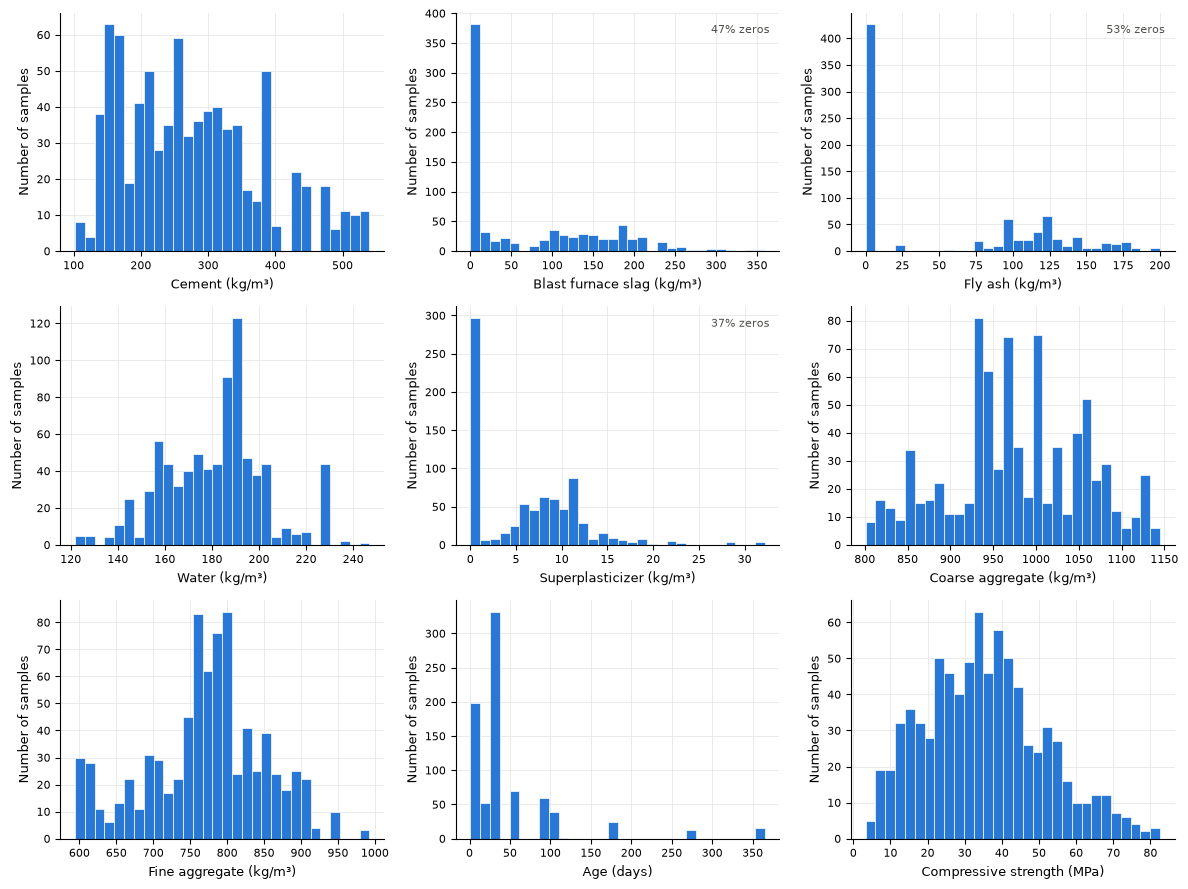

**Figura 1.** Distribución de las variables en train-val (805 muestras). En las variables que tienen ceros se indica el porcentaje de mezclas que no incluyen ese componente.

In [11]:
fig, axes = plt.subplots(3, 3, figsize=(12, 9))
for ax, column in zip(axes.flat, COLUMNS):
    ax.hist(train_val_df[column], bins=30, color=COLOR_TRAIN, edgecolor="white", linewidth=0.5)
    ax.set_xlabel(LABELS[column])
    ax.set_ylabel("Number of samples")
    zero_share = (train_val_df[column] == 0).mean()
    if zero_share > 0:
        ax.text(0.97, 0.95, f"{zero_share:.0%} zeros", transform=ax.transAxes,
                ha="right", va="top", fontsize=8, color=COLOR_MUTED)
fig.tight_layout()
show_figure(fig, 1,
            f"Distribución de las variables en train-val ({len(train_val_df)} muestras). En las variables "
            "que tienen ceros se indica el porcentaje de mezclas que no incluyen ese componente.")

Observaciones de la Figura 1:

- **Escalas muy distintas.** El agregado grueso está entre 801 y 1145 kg/m³, mientras que el superplastificante está entre 0 y 32 kg/m³ y la edad entre 1 y 365 días. Para entrenar una red neuronal hay que llevar todas las variables a una escala comparable (sección 4).
- **Muchos ceros.** El 47 % de las mezclas no tiene escoria, el 53 % no tiene ceniza volante y el 37 % no tiene superplastificante. Estas variables tienen dos grupos: las mezclas que no incluyen el componente y las que sí lo incluyen en distintas cantidades.
- **La edad está muy sesgada hacia valores bajos** y solo toma unos pocos valores. Se analiza con más detalle en la Figura 2.
- **La resistencia** va de 3.3 a 82.6 MPa, con una distribución unimodal y ligeramente sesgada a la derecha.

**Edades de ensayo**

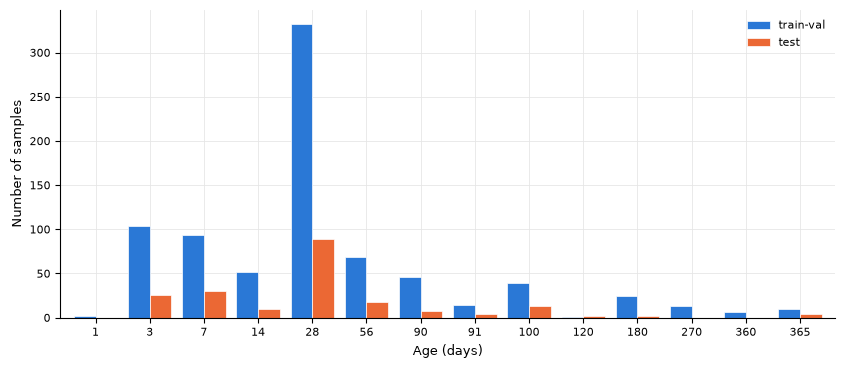

**Figura 2.** Número de muestras en cada edad del concreto, en train-val y en prueba.

Distinct ages in train-val: 14
Test ages not present in train-val: none


In [12]:
# The age only takes a few discrete values: count the samples at each age
age_counts = (pd.DataFrame({"train-val": train_val_df["age"].value_counts(),
                            "test": test_df["age"].value_counts()})
              .fillna(0).astype(int).sort_index())

ax = age_counts.plot.bar(figsize=(10, 4), color=[COLOR_TRAIN, COLOR_TEST],
                         width=0.8, edgecolor="white", linewidth=0.5)
ax.set_xlabel(LABELS["age"])
ax.set_ylabel("Number of samples")
ax.tick_params(axis="x", rotation=0)
show_figure(ax.figure, 2, "Número de muestras en cada edad del concreto, en train-val y en prueba.")

print(f"Distinct ages in train-val: {train_val_df['age'].nunique()}")
print(f"Test ages not present in train-val: "
      f"{sorted(set(test_df['age']) - set(train_val_df['age'])) or 'none'}")

Observaciones de la Figura 2:

- La edad solo toma **14 valores distintos**, que corresponden a las edades de ensayo habituales en laboratorio (3, 7, 14, 28, 56, 90 días, etc.). Por eso puede tratarse como una variable numérica o como una variable categórica (one-hot), alternativa que se compara en la sección 8.2.
- La edad de **28 días**, que es la edad de referencia para especificar la resistencia del concreto, concentra cerca del 40 % de las muestras. Algunas edades tienen muy pocas muestras (1 día: 2 muestras; 120 días: 1 muestra).
- Todas las edades del conjunto de prueba aparecen en train-val, así que una codificación one-hot no encontraría categorías desconocidas al evaluar en prueba.

**Correlación entre variables**

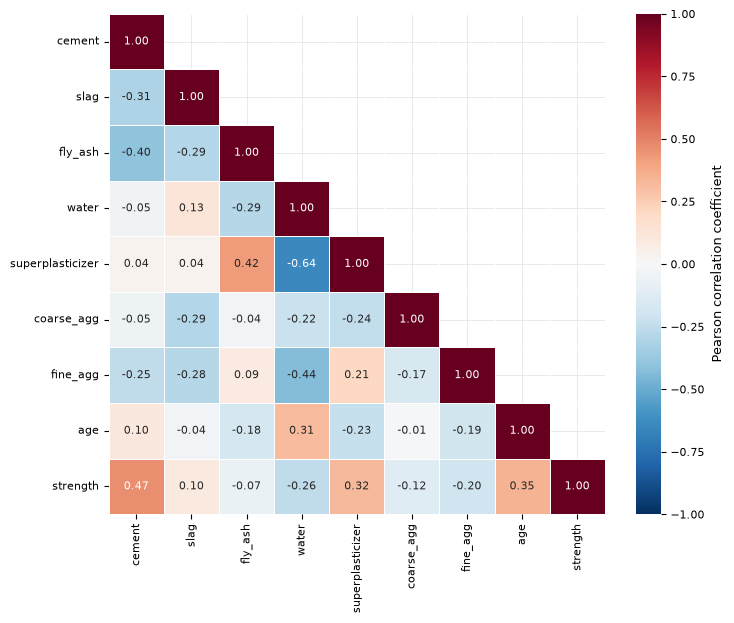

**Figura 3.** Coeficientes de correlación de Pearson entre las variables de train-val.

In [13]:
correlation = train_val_df.corr(method="pearson")
upper_triangle = np.triu(np.ones_like(correlation, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(correlation, mask=upper_triangle, cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 8}, linewidths=0.5, linecolor="white",
            cbar_kws={"label": "Pearson correlation coefficient"}, ax=ax)
show_figure(fig, 3, "Coeficientes de correlación de Pearson entre las variables de train-val.")

Los valores de la Figura 3 son coeficientes de correlación de Pearson. Para dos variables $x$ y $y$ se calculan con la Ecuación (1):

$$
r_{xy} = \frac{\sum_{i=1}^{m}(x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^{m}(x_i - \bar{x})^2}\,\sqrt{\sum_{i=1}^{m}(y_i - \bar{y})^2}} \tag{1}
$$

donde $m$ es el número de muestras, $x_i$ y $y_i$ son los valores de la muestra $i$, y $\bar{x}$ y $\bar{y}$ son las medias. Toma valores entre $-1$ y $1$ y **solo mide relaciones lineales**.

Observaciones de la Figura 3:

- Ninguna variable explica por sí sola la resistencia. Las correlaciones más altas con la resistencia son las del cemento ($r = 0.47$), la edad ($0.35$) y el superplastificante ($0.32$), y la del agua es negativa ($-0.26$). Las demás son débiles.
- Que las correlaciones lineales sean moderadas no significa que las variables no influyan: la resistencia depende de **combinaciones** de componentes (por ejemplo, la relación agua/cemento) y de relaciones no lineales, como la de la edad. Esto justifica usar un modelo no lineal como una red neuronal.
- La correlación más fuerte entre entradas es la del agua con el superplastificante ($-0.64$): el superplastificante se usa justamente para reducir el agua necesaria sin perder trabajabilidad. Ninguna otra pareja de entradas tiene una correlación tan alta como para considerarla redundante.

**Resistencia vs. edad**

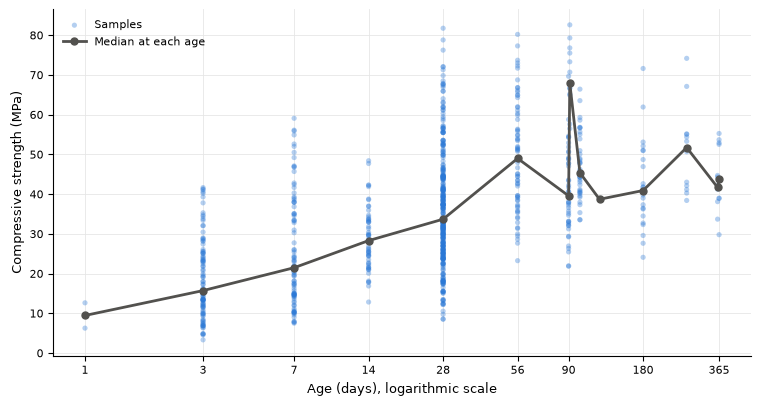

**Figura 4.** Resistencia a compresión vs. edad en train-val, con el eje horizontal en escala logarítmica. La línea gris une las medianas de cada edad.

Pearson r between strength and age:     0.35
Pearson r between strength and ln(age): 0.56


In [14]:
median_by_age = train_val_df.groupby("age")[TARGET].median()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(train_val_df["age"], train_val_df[TARGET], s=14, alpha=0.35,
           color=COLOR_TRAIN, edgecolors="none", label="Samples")
ax.plot(median_by_age.index, median_by_age.values, color=COLOR_MUTED, linewidth=2,
        marker="o", markersize=5, label="Median at each age")
ax.set_xscale("log")
# Label only a subset of ages so that close values (90/91/100, 360/365) do not overlap
AGE_TICKS = [1, 3, 7, 14, 28, 56, 90, 180, 365]
ax.set_xticks(AGE_TICKS)
ax.set_xticklabels(AGE_TICKS)
ax.minorticks_off()
ax.set_xlabel(LABELS["age"] + ", logarithmic scale")
ax.set_ylabel(LABELS[TARGET])
ax.legend(loc="upper left")
show_figure(fig, 4,
            "Resistencia a compresión vs. edad en train-val, con el eje horizontal en escala logarítmica. "
            "La línea gris une las medianas de cada edad.")

r_age = train_val_df["age"].corr(train_val_df[TARGET])
r_log_age = np.log(train_val_df["age"]).corr(train_val_df[TARGET])
print(f"Pearson r between strength and age:     {r_age:.2f}")
print(f"Pearson r between strength and ln(age): {r_log_age:.2f}")

Observaciones de la Figura 4:

- La resistencia crece rápido durante los primeros 28 días y después crece cada vez más lento, que es el comportamiento conocido del curado del concreto.
- En escala logarítmica la tendencia se parece más a una recta: la correlación con $\ln(\text{edad})$ ($r = 0.56$) es mayor que con la edad en días ($r = 0.35$). Esto coincide con la fórmula de regresión de Yeh (1998), que usa el término $\ln(t)$, y sugiere transformar la edad antes de entrenar la red (sección 8.2).
- Después de los 56 días la mediana sube y baja (por ejemplo, 67.9 MPa a los 91 días y 45.4 MPa a los 100 días). Esto no significa que el concreto pierda resistencia: cada edad incluye mezclas distintas, así que estas diferencias se deben a la dosificación y no a la edad.
- Para una misma edad la dispersión es grande (a los 28 días hay resistencias de menos de 10 MPa y de más de 80 MPa), lo que confirma que la edad por sí sola no basta para predecir la resistencia.

**Resistencia vs. relaciones agua/cemento y agua/aglomerante**

La ley de Abrams establece que la resistencia del concreto disminuye cuando aumenta la relación agua/cemento. Yeh (1998) muestra que, en concretos con escoria y ceniza volante, la relación agua/aglomerante predice mejor la resistencia. Ambas relaciones se definen con las Ecuaciones (2) y (3):

$$
\frac{w}{c} = \frac{W}{C} \tag{2}
$$

$$
\frac{w}{b} = \frac{W}{B} = \frac{W}{C + S + F} \tag{3}
$$

donde $W$ es la masa de agua, $C$ la de cemento, $S$ la de escoria de alto horno y $F$ la de ceniza volante, todas en kg por m³ de mezcla, y $B = C + S + F$ es la masa total de aglomerante. Aquí se calculan solo para graficarlas; su uso como variables de entrada se evalúa en la sección 8.1.

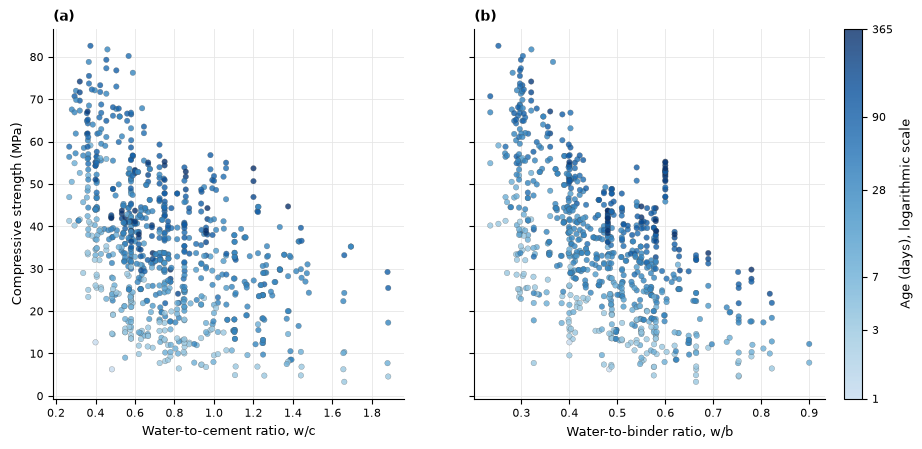

**Figura 5.** Resistencia a compresión vs. (a) relación agua/cemento y (b) relación agua/aglomerante, en train-val. El color indica la edad del concreto. Coeficiente de correlación de Pearson: (a) r = -0.47; (b) r = -0.59.

In [15]:
# Sequential blue scale without its near-white end, so that young samples stay visible
AGE_CMAP = ListedColormap(plt.get_cmap("Blues")(np.linspace(0.25, 1.0, 256)))

binder = train_val_df["cement"] + train_val_df["slag"] + train_val_df["fly_ash"]
ratios = {
    "Water-to-cement ratio, w/c": train_val_df["water"] / train_val_df["cement"],
    "Water-to-binder ratio, w/b": train_val_df["water"] / binder,
}

r_ratios = {name: ratio.corr(train_val_df[TARGET]) for name, ratio in ratios.items()}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, panel, (name, ratio) in zip(axes, ["(a)", "(b)"], ratios.items()):
    points = ax.scatter(ratio, train_val_df[TARGET], c=train_val_df["age"], cmap=AGE_CMAP,
                        norm=LogNorm(vmin=1, vmax=365), s=16, alpha=0.8,
                        edgecolors=COLOR_MUTED, linewidths=0.2)
    ax.set_xlabel(name)
    ax.set_title(panel, loc="left", fontweight="bold")
axes[0].set_ylabel(LABELS[TARGET])
colorbar = fig.colorbar(points, ax=axes, pad=0.02)
colorbar.set_ticks([1, 3, 7, 28, 90, 365])
colorbar.set_ticklabels(["1", "3", "7", "28", "90", "365"])
colorbar.minorticks_off()
colorbar.set_label(LABELS["age"] + ", logarithmic scale")
r_wc, r_wb = r_ratios.values()
show_figure(fig, 5,
            "Resistencia a compresión vs. (a) relación agua/cemento y (b) relación agua/aglomerante, "
            "en train-val. El color indica la edad del concreto. Coeficiente de correlación de Pearson: "
            f"(a) r = {r_wc:.2f}; (b) r = {r_wb:.2f}.")

Observaciones de la Figura 5:

- En ambas gráficas la resistencia disminuye cuando aumenta la relación, como predice la ley de Abrams.
- La relación agua/aglomerante tiene una correlación más fuerte con la resistencia ($r = -0.59$) que la relación agua/cemento ($r = -0.47$) y que cualquiera de las 8 variables originales (la mayor es la del cemento, $r = 0.47$). Esto coincide con lo que reporta Yeh (1998) y la convierte en una buena candidata como variable de entrada adicional (sección 8.1).
- Para una misma relación, buena parte de la dispersión vertical se explica por la edad: los puntos más oscuros (mayor edad) tienden a estar arriba. La red neuronal tendrá que combinar ambos efectos.

### 2.4 Observaciones del análisis exploratorio

> *Pendiente: conclusiones que guían el preprocesamiento y la ingeniería de variables.*

## 3. Métrica de evaluación

> *Pendiente: definición del RMSE (en LaTeX, con el significado de cada símbolo) y justificación de por qué es la métrica única para comparar modelos.*

## 4. Metodología de validación cruzada

> *Pendiente: explicación del k-fold, preprocesamiento dentro del `Pipeline` para evitar fuga de datos, función `evaluate` y tabla acumulada de experimentos, y criterio de diagnóstico de sesgo y varianza.*

## 5. Modelos de referencia

> *Pendiente: `DummyRegressor` (predice la media) y regresión lineal, como escala para juzgar los resultados de la red.*

## 6. Red neuronal base

> *Pendiente: arquitectura inicial (p. ej., 1 capa oculta de 8 neuronas, como Yeh), ecuaciones de propagación hacia adelante y función de costo, y resultado de validación cruzada.*

## 7. Diagnóstico de sesgo y varianza

### 7.1 Curva de aprendizaje

> *Pendiente: RMSE de entrenamiento y validación vs. número de muestras de entrenamiento.*

### 7.2 Curvas de validación

> *Pendiente: RMSE vs. número de neuronas y vs. parámetro de regularización $\alpha$.*

### 7.3 Curva de pérdida

> *Pendiente: evolución de la función de costo durante el entrenamiento para verificar la convergencia.*

### 7.4 Interpretación

> *Pendiente: diagnóstico del modelo base y estrategias a probar en la sección 8.*

## 8. Mejora del modelo

### 8.1 Nuevas variables de entrada

> *Pendiente: relaciones w/c, w/b, SP/b, escoria/b, ceniza/b y agregados/b.*

### 8.2 Tratamiento de la edad

> *Pendiente: edad cruda vs. $\ln(\text{edad})$ vs. one-hot de los 14 valores de edad.*

### 8.3 Escalado de entradas y salida

> *Pendiente: `StandardScaler` vs. `MinMaxScaler`, con y sin escalado de la resistencia.*

### 8.4 Arquitectura de la red

> *Pendiente: número de capas ocultas y de neuronas.*

### 8.5 Función de activación

> *Pendiente: `relu` vs. `tanh`.*

### 8.6 Optimizador y tasa de aprendizaje

> *Pendiente: `adam` vs. `sgd`, distintos valores de `learning_rate_init` y tasa adaptativa.*

### 8.7 Regularización

> *Pendiente: barrido de $\alpha$ (L2) y `early_stopping`.*

### 8.8 Búsqueda conjunta de hiperparámetros

> *Pendiente: `GridSearchCV` o `RandomizedSearchCV` con las mismas particiones k-fold.*

### 8.9 Resumen de experimentos

> *Pendiente: tabla de todos los experimentos ordenada por RMSE de validación cruzada y gráfica comparativa.*

## 9. Modelo final y evaluación en el conjunto de prueba

### 9.1 Entrenamiento del modelo final

> *Pendiente: reentrenamiento del mejor pipeline con todo train-val y su curva de aprendizaje.*

### 9.2 Desempeño en el conjunto de prueba

> *Pendiente: RMSE (y R², MAE como complemento) en prueba, comparado con el RMSE de validación cruzada; resultado también sin las filas repetidas entre train-val y test.*

### 9.3 Análisis de las predicciones

> *Pendiente: gráfico de paridad predicho vs. medido, residuos vs. predicción y vs. edad, y comparación con los resultados de Yeh (1998).*

## 10. Conclusiones

> *Pendiente: qué mejoró más el modelo, diagnóstico final de sesgo y varianza, limitaciones y trabajo futuro.*

## Referencias

- Yeh, I.C., 1998. Modeling of strength of high-performance concrete using artificial neural networks. *Cement and Concrete Research*, 28(12), pp. 1797-1808.